# import libraries 

In [ ]:
import numpy as np 
import pandas as pd 
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import load_iris
from sklearn.tree import DecisionTreeClassifier
from sklearn.tree import plot_tree
from mlxtend.plotting import plot_decision_regions
from sklearn.metrics import accuracy_score

# import dataset

In [76]:
df = sns.load_dataset('iris')
df.head()

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa


In [ ]:
# do label encoding of the categories
from sklearn.preprocessing import LabelEncoder
encoder = LabelEncoder()
encoder.fit_transform(df['species'])

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1,
       1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 1, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2,
       2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2, 2])

In [78]:
df['species'] = encoder.fit_transform(df['species'])

In [79]:
df

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,0
1,4.9,3.0,1.4,0.2,0
2,4.7,3.2,1.3,0.2,0
3,4.6,3.1,1.5,0.2,0
4,5.0,3.6,1.4,0.2,0
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,2
146,6.3,2.5,5.0,1.9,2
147,6.5,3.0,5.2,2.0,2
148,6.2,3.4,5.4,2.3,2


In [80]:
df.columns

Index(['sepal_length', 'sepal_width', 'petal_length', 'petal_width',
       'species'],
      dtype='object')

In [81]:
df = df[['sepal_width', 'petal_length','species']]
df

,sepal_width,petal_length,species
0,3.5,1.4,0
1,3.0,1.4,0
2,3.2,1.3,0
3,3.1,1.5,0
4,3.6,1.4,0
...,...,...,...
145,3.0,5.2,2
146,2.5,5.0,2
147,3.0,5.2,2
148,3.4,5.4,2


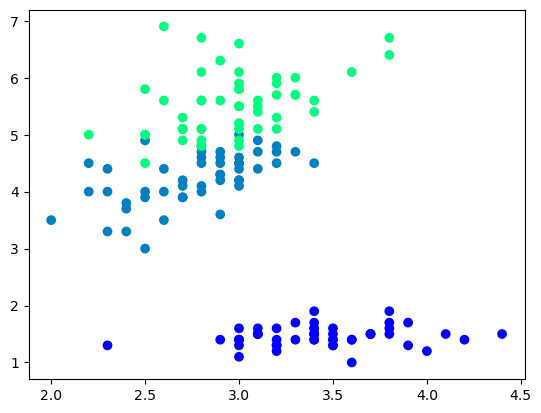

In [82]:
plt.scatter(df['sepal_width'],df['petal_length'],c=df['species'],cmap='winter')
plt.show()

we shuffle our data  because our data in sequence of categories order 0 ,1,2

In [83]:
df_train = df.iloc[:60,:].sample(10)
df_train

,sepal_width,petal_length,species
58,2.9,4.6,1
10,3.7,1.5,0
54,2.8,4.6,1
31,3.4,1.5,0
42,3.2,1.3,0
9,3.1,1.5,0
35,3.2,1.2,0
59,2.7,3.9,1
30,3.1,1.6,0
53,2.3,4.0,1


In [84]:
# Taking only 10 rows for training
df = df.sample(100)
df_train = df.iloc[:60,:].sample(10) # Training Set
df_val = df.iloc[60:80,:].sample(5) # Validation Set
df_test = df.iloc[80:,:].sample(5)  # Testing Set

In [85]:
df_train

,sepal_width,petal_length,species
25,3.0,1.6,0
114,2.8,5.1,2
21,3.7,1.5,0
116,3.0,5.5,2
56,3.3,4.7,1
19,3.8,1.5,0
47,3.2,1.4,0
136,3.4,5.6,2
40,3.5,1.3,0
134,2.6,5.6,2


In [86]:
X_test = df_val.iloc[:,0:2].values
y_test = df_val.iloc[:,-1].values

# Bagging 
we make 3 decesion Tree algrotihums

we have data of 10 rows we train the decesion Tree on it . 
Now we give 80 % of the data for training .
every decesion gets 8 rows

In [87]:
df_bag = df_train.sample(8,replace = True) # replacement sampling

X = df_bag.iloc[: ,0:2]
y = df_bag.iloc[:,-1]

df_bag

,sepal_width,petal_length,species
114,2.8,5.1,2
21,3.7,1.5,0
21,3.7,1.5,0
136,3.4,5.6,2
136,3.4,5.6,2
136,3.4,5.6,2
116,3.0,5.5,2
40,3.5,1.3,0


In [89]:
def evaluate(clf,X,y):
    clf.fit(X,y)
    plot_tree(clf)
    plt.show()
    plot_decision_regions(X.values, y.values, clf=clf, legend=2)
    y_pred = clf.predict(X_test)
    print(accuracy_score(y_test,y_pred))

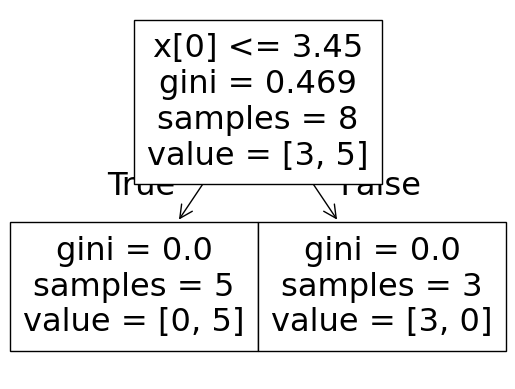

c:\Users\sumit\miniconda3\envs\my_env\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\sumit\miniconda3\envs\my_env\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


0.4


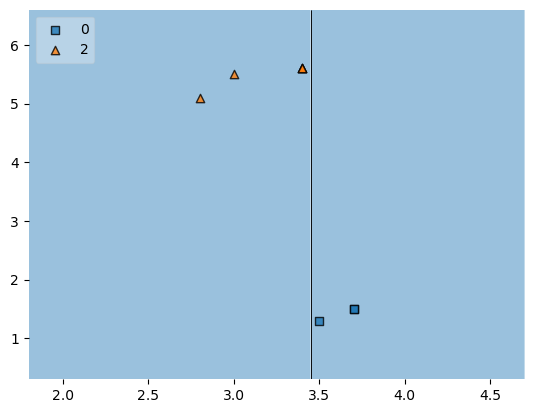

In [90]:
dt_bag1 = DecisionTreeClassifier()
evaluate(dt_bag1,X,y)

repeat the work for another decesion tree

In [91]:
# Data for Tree 2
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

df_bag

,sepal_width,petal_length,species
47,3.2,1.4,0
21,3.7,1.5,0
47,3.2,1.4,0
25,3.0,1.6,0
56,3.3,4.7,1
47,3.2,1.4,0
25,3.0,1.6,0
19,3.8,1.5,0


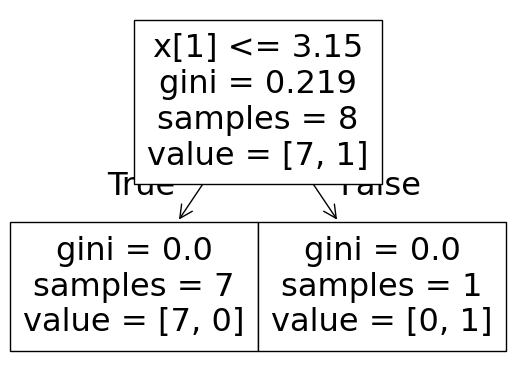

c:\Users\sumit\miniconda3\envs\my_env\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\sumit\miniconda3\envs\my_env\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


1.0


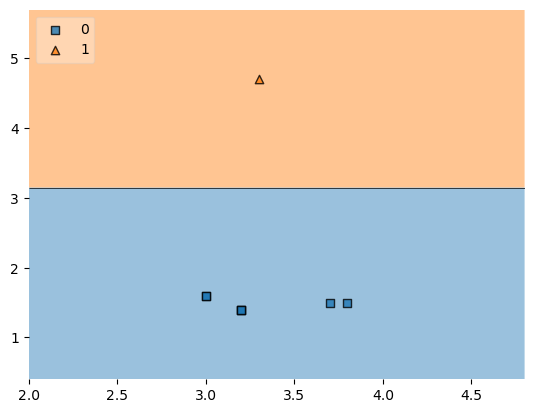

In [92]:
dt_bag2 = DecisionTreeClassifier()
evaluate(dt_bag2,X,y)

In [93]:
# Data for Tree 3
df_bag = df_train.sample(8,replace=True)

# Fetch X and y
X = df_bag.iloc[:,0:2]
y = df_bag.iloc[:,-1]

# print df_bag
df_bag

,sepal_width,petal_length,species
56,3.3,4.7,1
21,3.7,1.5,0
47,3.2,1.4,0
116,3.0,5.5,2
136,3.4,5.6,2
21,3.7,1.5,0
40,3.5,1.3,0
116,3.0,5.5,2


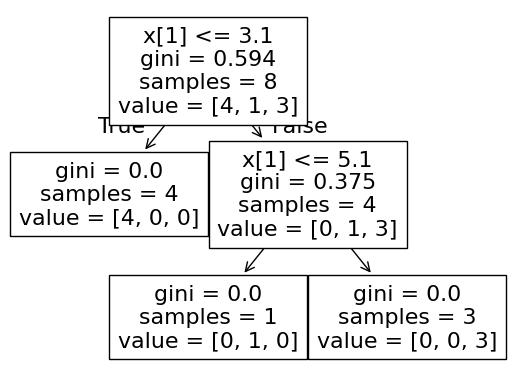

c:\Users\sumit\miniconda3\envs\my_env\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\sumit\miniconda3\envs\my_env\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


1.0


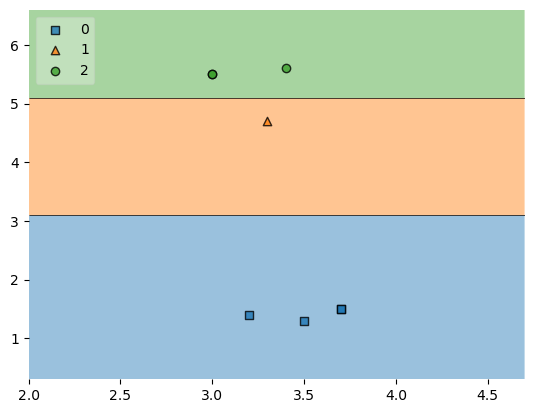

In [94]:
dt_bag3 = DecisionTreeClassifier()
evaluate(dt_bag3,X,y)

# Aggreation 

In [95]:
df_test

,sepal_width,petal_length,species
65,3.1,4.4,1
141,3.1,5.1,2
31,3.4,1.5,0
64,2.9,3.6,1
78,2.9,4.5,1


example human ek point da diya 2.2 ,4.0 jiska outputput huma pata ha  1


In [96]:
print("Predictor 1",dt_bag1.predict(np.array([2.2,5.0]).reshape(1,2)))
print("Predictor 2",dt_bag2.predict(np.array([2.2,5.0]).reshape(1,2)))
print("Predictor 3",dt_bag3.predict(np.array([2.2,5.0]).reshape(1,2)))

Predictor 1 [2]
Predictor 2 [1]
Predictor 3 [1]


c:\Users\sumit\miniconda3\envs\my_env\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\sumit\miniconda3\envs\my_env\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(
c:\Users\sumit\miniconda3\envs\my_env\Lib\site-packages\sklearn\utils\validation.py:2739: UserWarning: X does not have valid feature names, but DecisionTreeClassifier was fitted with feature names
  warnings.warn(


Types of Bagging based on type of subset you create
sampling is different           
currently you do row sampling with replacemnt           
if you have large dimension of data . you also do th column sampling .  you have image ,text 

# Types of Bagging

## Pasting 
you do row sapmling but without replacement.

In [97]:
df_train

,sepal_width,petal_length,species
25,3.0,1.6,0
114,2.8,5.1,2
21,3.7,1.5,0
116,3.0,5.5,2
56,3.3,4.7,1
19,3.8,1.5,0
47,3.2,1.4,0
136,3.4,5.6,2
40,3.5,1.3,0
134,2.6,5.6,2


In [ ]:
df_train.sample(8) # default is sampling without replacemnt

,sepal_width,petal_length,species
134,2.6,5.6,2
21,3.7,1.5,0
40,3.5,1.3,0
19,3.8,1.5,0
47,3.2,1.4,0
25,3.0,1.6,0
136,3.4,5.6,2
114,2.8,5.1,2


## Random Subspaces
you do column  sampling with replacemnt or without replacemnt dono

In [104]:
data = sns.load_dataset('iris')
data

,sepal_length,sepal_width,petal_length,petal_width,species
0,5.1,3.5,1.4,0.2,setosa
1,4.9,3.0,1.4,0.2,setosa
2,4.7,3.2,1.3,0.2,setosa
3,4.6,3.1,1.5,0.2,setosa
4,5.0,3.6,1.4,0.2,setosa
...,...,...,...,...,...
145,6.7,3.0,5.2,2.3,virginica
146,6.3,2.5,5.0,1.9,virginica
147,6.5,3.0,5.2,2.0,virginica
148,6.2,3.4,5.4,2.3,virginica


In [108]:
data.sample(2,replace = True , axis = 1) 
# axis - 1 meaning column sampling
# axis - 0 meaning row sampling

,species,sepal_length
0,setosa,5.1
1,setosa,4.9
2,setosa,4.7
3,setosa,4.6
4,setosa,5.0
...,...,...
145,virginica,6.7
146,virginica,6.3
147,virginica,6.5
148,virginica,6.2


In [ ]:
# run it and see the experimentally

##  Random Paches
you do both row and column sampling 

In [109]:
data = sns.load_dataset('iris')
data.sample(10)

,sepal_length,sepal_width,petal_length,petal_width,species
130,7.4,2.8,6.1,1.9,virginica
91,6.1,3.0,4.6,1.4,versicolor
69,5.6,2.5,3.9,1.1,versicolor
23,5.1,3.3,1.7,0.5,setosa
124,6.7,3.3,5.7,2.1,virginica
19,5.1,3.8,1.5,0.3,setosa
2,4.7,3.2,1.3,0.2,setosa
80,5.5,2.4,3.8,1.1,versicolor
51,6.4,3.2,4.5,1.5,versicolor
93,5.0,2.3,3.3,1.0,versicolor


In [112]:
data.sample(8,replace=True).sample(2,replace=True,axis=1)

,petal_width,petal_width
106,1.7,1.7
129,1.6,1.6
124,2.1,2.1
11,0.2,0.2
48,0.2,0.2
105,2.1,2.1
53,1.3,1.3
40,0.3,0.3
